# Import Statements

In [ ]:
# ==========================================
# 1. Import Required Libraries and Modules
# ==========================================

# Operating system utilities
import os

# Deep Learning framework (Keras & layers)
import keras
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

# Image processing and data manipulation libraries
from PIL import Image
import numpy as np
import pandas as pd

# Data visualization library and dark theme configuration
import matplotlib.pyplot as plt
plt.style.use('dark_background')

# Scikit-Learn utilities for data splitting, encoding, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score


# One Hot Encoding the Target Classes

In [ ]:
# ==========================================
# 2. Initialize and Fit the One-Hot Encoder
# ==========================================

# Initialize the OneHotEncoder to convert categorical labels into numerical vectors
encoder = OneHotEncoder()

# Fit the encoder on possible label classes:
# 0 -> Tumor 
# 1 -> Normal 
encoder.fit([[0], [1]])
# Label mapping reference:
# 0 - Tumor
# 1 - Normal


,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequent

# Import Dataset

# Creating 3 Important Lists --
1. data list for storing image data in numpy array form
2. paths list for storing paths of all images
3. result list for storing one hot encoded form of target class whether normal or tumor

In [ ]:
# ==========================================
# 3. Load and Preprocess Tumor Images ('yes')
# ==========================================

# Initialize lists to store image data, file paths, and encoded target labels
data = []
paths = []
result = []

# Walk through the directory to find all .jpg images containing tumors
for r, d, f in os.walk(r"C:/Project/Brain_MRI_Tumor_dataset/create_model/brain_tumor_dataset/Training/yes"):
    for file in f:
        if '.jpg' in file:
            paths.append(os.path.join(r, file))

# Process each image path: open, resize, convert to array, and validate shape
for path in paths:
    img = Image.open(path)
    img = img.resize((128, 128))  # Resize all images to a uniform 128x128 resolution
    img = np.array(img)
    
    # Check if the image has the expected 3-channel RGB shape
    if img.shape == (128, 128, 3):
        data.append(np.array(img))
        # Assign encoded label for tumor (Class 0) and append to results
        result.append(encoder.transform([[0]]).toarray())


In [ ]:
# ==========================================
# 4. Load and Preprocess Non-Tumor Images ('no')
# ==========================================

# Clear or re-initialize paths list for the normal images directory
paths = []

# Walk through the directory to find all .jpg images without tumors
for r, d, f in os.walk(r"C:/Project/Brain_MRI_Tumor_detection/create_model/brain_tumor_dataset/Training/no"):
    for file in f:
        if '.jpg' in file:
            paths.append(os.path.join(r, file))

# Process each image path: open, resize, convert to array, and validate shape
for path in paths:
    img = Image.open(path)
    img = img.resize((128, 128))  # Resize all images to a uniform 128x128 resolution
    img = np.array(img)
    
    # Check if the image has the expected 3-channel RGB shape
    if img.shape == (128, 128, 3):
        data.append(np.array(img))
        # Assign encoded label for normal (Class 1) and append to results
        result.append(encoder.transform([[1]]).toarray())


### Data shape

In [ ]:
# ==========================================
# 5. Convert Data to NumPy Array and Check Shape
# ==========================================

# Convert the list of images into a NumPy array for model training
data = np.array(data)

# Output the shape of the dataset (e.g., (num_samples, height, width, channels))
data.shape


(2891, 128, 128, 3)

### Data reshape

In [ ]:
# ==========================================
# 6. Convert Results to NumPy Array and Reshape
# ==========================================

# Convert the list of encoded results into a NumPy array
result = np.array(result)

# Reshape the result array to a 2D structure (e.g., matching the number of samples to 2 classes)
result = result.reshape(2891, 2)


In [24]:
result.shape

(2891, 2)

# Splitting the Data into Training & Testing

In [ ]:
# ==========================================
# 7. Split Dataset into Training and Testing Sets
# ==========================================

# Split the image data and labels into train (80%) and test (20%) sets, 
# with shuffling enabled and a fixed random state for reproducibility
x_train, x_test, y_train, y_test = train_test_split(
    data, 
    result, 
    test_size=0.2, 
    shuffle=True, 
    random_state=42
)


# Model Building : CNN

Batch normalization is a technique for training very deep neural networks that standardizes the inputs to a layer for each mini-batch. This has the effect of stabilizing the learning process and dramatically reducing the number of training epochs required to train deep networks.

In [ ]:
# ==========================================
# 8. Build the Convolutional Neural Network (CNN) Model
# ==========================================

# Initialize a sequential model
model = Sequential()
input_shape = (128, 128, 3)

# --- First Convolutional Block ---
model.add(Conv2D(32, kernel_size=(2, 2), input_shape=input_shape, padding='Same'))
model.add(Conv2D(32, kernel_size=(2, 2), activation='relu', padding='Same'))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

# --- Second Convolutional Block ---
model.add(Conv2D(64, kernel_size=(2, 2), activation='relu', padding='Same'))
model.add(Conv2D(64, kernel_size=(2, 2), activation='relu', padding='Same'))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.25))

# --- Fully Connected (Dense) Layers ---
model.add(Flatten())

model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))

# Output layer with 2 classes (Tumor / Normal) and softmax activation for multi-class/binary probability
model.add(Dense(2, activation='softmax'))


c:\Project\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# ==========================================
# 9. Compile the Model and Print Summary
# ==========================================

# Compile the model using categorical crossentropy loss, Adamax optimizer, and accuracy metric
model.compile(loss="categorical_crossentropy", optimizer='Adamax', metrics=['accuracy'])

# Print a summary of the model architecture, layers, and total trainable parameters
print(model.summary())


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 64)     │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    33,554,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,585,602 (128.12 MB)

 Trainable params: 33,585,410 (128.12 MB)

 Non-trainable params: 192 (768.00 B)

None


In [47]:
y_train.shape

(2312, 2)

In [28]:
history = model.fit(x_train, y_train, epochs = 5, verbose = 1,validation_data = (x_test, y_test))

Epoch 1/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 34s 446ms/step - accuracy: 0.7928 - loss: 5.6833 - val_accuracy: 0.8532 - val_loss: 1.9465
Epoch 2/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 447ms/step - accuracy: 0.9161 - loss: 0.6909 - val_accuracy: 0.9154 - val_loss: 0.3134
Epoch 3/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 448ms/step - accuracy: 0.9451 - loss: 0.2114 - val_accuracy: 0.9568 - val_loss: 0.1562
Epoch 4/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 448ms/step - accuracy: 0.9693 - loss: 0.1529 - val_accuracy: 0.9482 - val_loss: 0.1653
Epoch 5/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 33s 448ms/step - accuracy: 0.9706 - loss: 0.1162 - val_accuracy: 0.9724 - val_loss: 0.0886


# Plotting Accuracy and Loss

In [ ]:
# ==========================================
# 10. Inspect Training History Keys
# ==========================================

# Iterate through the training history dictionary and print available keys (e.g., loss, accuracy, val_loss, val_accuracy)
for key, val in history.history.items():
    print(key)


accuracy
loss
val_accuracy
val_loss


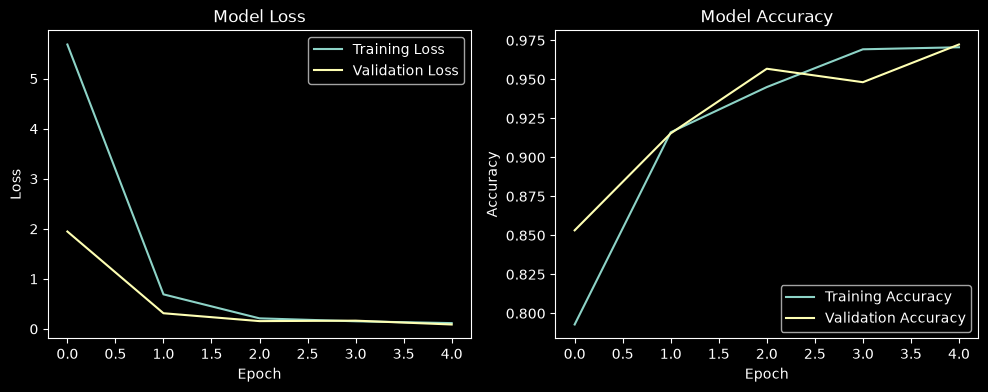

In [ ]:
# ==========================================
# 11. Plot Training and Validation Metrics
# ==========================================

# Create a figure for plotting the metrics with a specific size
plt.figure(figsize=(12, 4))

# --- Subplot 1: Training and Validation Loss ---
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper right')

# --- Subplot 2: Training and Validation Accuracy ---
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')

# Display the plotted graphs
plt.show()


# Just Checking the Model

In [ ]:
# ==========================================
# 12. Define Prediction Label Mapping Function
# ==========================================

# A helper function to convert numerical predictions back into readable diagnostic messages
def names(number):
    if number == 0:
        return 'Its a Tumor'        # Class 0 corresponds to the presence of a tumor
    else:
        return 'No, Its not a tumor' # Class 1 corresponds to normal / no tumor


### Its a Tumor

98.29919% Confidence This Is Its a Tumor


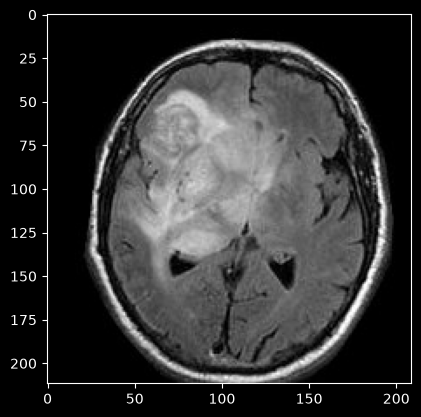

In [ ]:
# ==========================================
# 13. Predict Tumor on a New Single Image
# ==========================================

from matplotlib.pyplot import imshow

# Load a new test image from the prediction directory
img = Image.open(r"C:\Project\Brain_MRI_Tumor_detection\create_model\brain_tumor_dataset\Data_Prediction\yes\1.jpg")

# Resize the image to match the model's input requirement (128x128)
x = np.array(img.resize((128, 128)))

# Reshape the array to include the batch dimension: (1, height, width, channels)
x = x.reshape(1, 128, 128, 3)

# Perform prediction on the batch
res = model.predict_on_batch(x)

# Find the index of the class with the highest probability score
classification = np.where(res == np.amax(res))[1][0]

# Display the image visually
imshow(img)

# Print the confidence percentage alongside the predicted classification message
print(str(res[0][classification] * 100) + '% Confidence This Is ' + names(classification))


99.852646% Confidence This Is A Its a Tumor


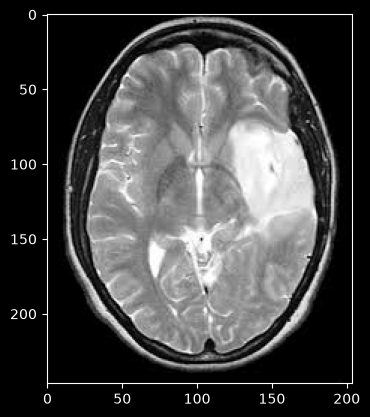

In [ ]:
# ==========================================
# 14. Predict Tumor on Another New Image
# ==========================================

from matplotlib.pyplot import imshow

# Load the second test image from the prediction directory
img = Image.open(r"C:\Project\Brain_MRI_Tumor_detection\create_model\brain_tumor_dataset\Data_Prediction\yes\2.jpg")

# Resize the image to match the model's required input dimensions (128x128)
x = np.array(img.resize((128, 128)))

# Reshape the array to include the batch dimension: (1, height, width, channels)
x = x.reshape(1, 128, 128, 3)

# Predict the class probabilities for the input image
res = model.predict_on_batch(x)

# Identify the class index with the highest probability
classification = np.where(res == np.amax(res))[1][0]

# Display the image visually
imshow(img)

# Print the confidence score percentage and the corresponding classification result
print(str(res[0][classification] * 100) + '% Confidence This Is A ' + names(classification))



99.97384% Confidence This Is A Its a Tumor


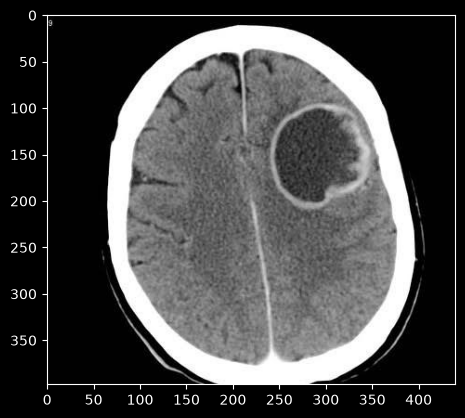

In [ ]:
# ==========================================
# 15. Predict Tumor on the Third Test Image
# ==========================================

from matplotlib.pyplot import imshow

# Load the third test image from the prediction directory
img = Image.open(r"C:\Project\Brain_MRI_Tumor_detection\create_model\brain_tumor_dataset\Data_Prediction\yes\3.jpg")

# Resize the image to match the model's required input dimensions (128x128)
x = np.array(img.resize((128, 128)))

# Reshape the array to include the batch dimension: (1, height, width, channels)
x = x.reshape(1, 128, 128, 3)

# Predict the class probabilities for the input image
res = model.predict_on_batch(x)

# Identify the class index with the highest probability
classification = np.where(res == np.amax(res))[1][0]

# Display the image visually
imshow(img)

# Print the confidence score percentage and the corresponding classification result
print(str(res[0][classification] * 100) + '% Confidence This Is A ' + names(classification))


99.99991% Confidence This Is A Its a Tumor


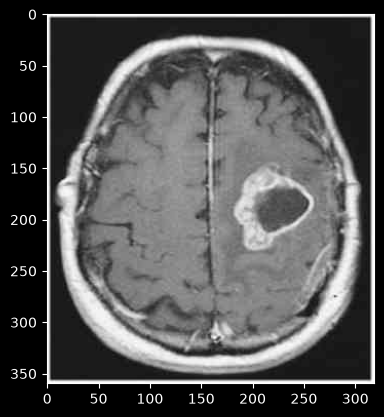

In [ ]:
# ==========================================
# 16. Predict Tumor on the Fourth Test Image
# ==========================================

from matplotlib.pyplot import imshow

# Load the fourth test image from the prediction directory
img = Image.open(r"C:\Project\Brain_MRI_Tumor_detection\create_model\brain_tumor_dataset\Data_Prediction\yes\4.jpg")

# Resize the image to match the model's required input dimensions (128x128)
x = np.array(img.resize((128, 128)))

# Reshape the array to include the batch dimension: (1, height, width, channels)
x = x.reshape(1, 128, 128, 3)

# Predict the class probabilities for the input image
res = model.predict_on_batch(x)

# Identify the class index with the highest probability
classification = np.where(res == np.amax(res))[1][0]

# Display the image visually
imshow(img)

# Print the confidence score percentage and the corresponding classification result
print(str(res[0][classification] * 100) + '% Confidence This Is A ' + names(classification))


### No, Its not a tumor

100.0% Confidence This Is A No, Its not a tumor


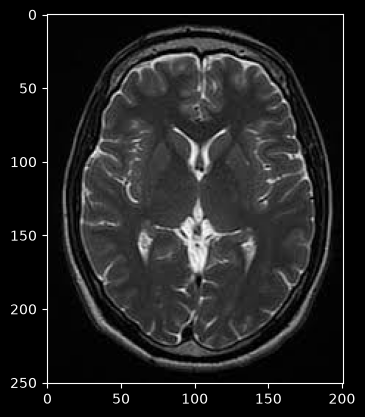

In [ ]:
# ==========================================
# 17. Predict Non-Tumor on the First Normal Test Image
# ==========================================

from matplotlib.pyplot import imshow

# Load the first normal/non-tumor test image from the prediction directory
img = Image.open(r"C:\Project\Brain_MRI_Tumor_detection\create_model\brain_tumor_dataset\Data_Prediction\no\1.jpg")

# Resize the image to match the model's required input dimensions (128x128)
x = np.array(img.resize((128, 128)))

# Reshape the array to include the batch dimension: (1, height, width, channels)
x = x.reshape(1, 128, 128, 3)

# Predict the class probabilities for the input image
res = model.predict_on_batch(x)

# Identify the class index with the highest probability
classification = np.where(res == np.amax(res))[1][0]

# Display the image visually
imshow(img)

# Print the confidence score percentage and the corresponding classification result
print(str(res[0][classification] * 100) + '% Confidence This Is A ' + names(classification))


100.0% Confidence This Is A No, Its not a tumor


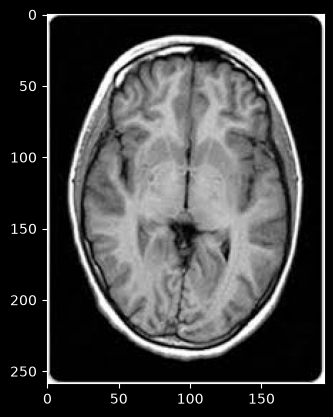

In [ ]:
# ==========================================
# 18. Predict Non-Tumor on the Second Normal Test Image
# ==========================================

from matplotlib.pyplot import imshow

# Load the second normal/non-tumor test image from the prediction directory
img = Image.open(r"C:\Project\Brain_MRI_Tumor_detection\create_model\brain_tumor_dataset\Data_Prediction\no\2.jpg")

# Resize the image to match the model's required input dimensions (128x128)
x = np.array(img.resize((128, 128)))

# Reshape the array to include the batch dimension: (1, height, width, channels)
x = x.reshape(1, 128, 128, 3)

# Predict the class probabilities for the input image
res = model.predict_on_batch(x)

# Identify the class index with the highest probability
classification = np.where(res == np.amax(res))[1][0]

# Display the image visually
imshow(img)

# Print the confidence score percentage and the corresponding classification result
print(str(res[0][classification] * 100) + '% Confidence This Is A ' + names(classification))


99.99977% Confidence This Is A No, Its not a tumor


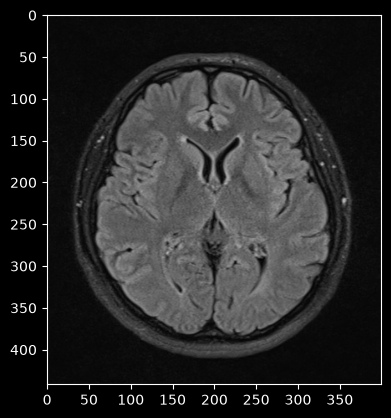

In [ ]:
# ==========================================
# 19. Predict Non-Tumor on the Third Normal Test Image (JPEG)
# ==========================================

from matplotlib.pyplot import imshow

# Load the third normal/non-tumor test image (with .jpeg extension) from the prediction directory
img = Image.open(r"C:\Project\Brain_MRI_Tumor_detection\create_model\brain_tumor_dataset\Data_Prediction\no\3.jpeg")

# Resize the image to match the model's required input dimensions (128x128)
x = np.array(img.resize((128, 128)))

# Reshape the array to include the batch dimension: (1, height, width, channels)
x = x.reshape(1, 128, 128, 3)

# Predict the class probabilities for the input image
res = model.predict_on_batch(x)

# Identify the class index with the highest probability
classification = np.where(res == np.amax(res))[1][0]

# Display the image visually
imshow(img)

# Print the confidence score percentage and the corresponding classification result
print(str(res[0][classification] * 100) + '% Confidence This Is A ' + names(classification))


91.17252% Confidence This Is A No, Its not a tumor


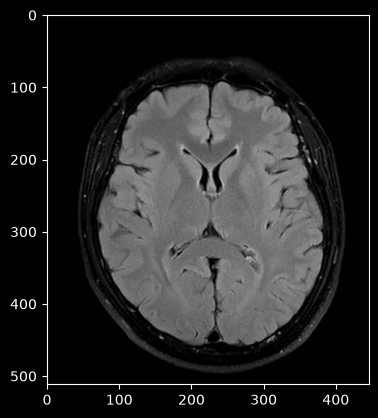

In [ ]:
# ==========================================
# 20. Predict Non-Tumor on the Fourth Normal Test Image
# ==========================================

from matplotlib.pyplot import imshow

# Load the fourth normal/non-tumor test image from the prediction directory
img = Image.open(r"C:\Project\Brain_MRI_Tumor_detection\create_model\brain_tumor_dataset\Data_Prediction\no\4.jpg")

# Resize the image to match the model's required input dimensions (128x128)
x = np.array(img.resize((128, 128)))

# Reshape the array to include the batch dimension: (1, height, width, channels)
x = x.reshape(1, 128, 128, 3)

# Predict the class probabilities for the input image
res = model.predict_on_batch(x)

# Identify the class index with the highest probability
classification = np.where(res == np.amax(res))[1][0]

# Display the image visually
imshow(img)

# Print the confidence score percentage and the corresponding classification result
print(str(res[0][classification] * 100) + '% Confidence This Is A ' + names(classification))


## Save the model

In [ ]:
# ==========================================
# 21. Save the Trained Model to Disk
# ==========================================

# Save the entire model (architecture, weights, and compilation configuration) to an HDF5 file
model.save("brain_tumor_model.h5")
    